---
title: "Лабораторна робота 7. Дизайн обчислювального експерименту та побудова hybrid/data-driven моделі"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

ЛР6 завершилася артефактом *Model Credibility Report v0.6*.

У ЛР7 переходимо від оцінювання вже побудованої моделі до *проєктування обчислювального дослідження* та порівняння різних способів представлення одного процесу:

$$
\text{Model Credibility Report v0.6}
\rightarrow
\text{Experimental Protocol}
\rightarrow
\text{mechanistic / data-driven / hybrid}
\rightarrow
\text{comparative evidence}.
$$

Методична ідея роботи:

$$
\boxed{
\text{hybrid model}
\neq
\text{mechanistic model}+\text{ML ``для покращення''}
}
$$

Data-driven component повинен мати чітко визначену роль і перевірятися в контрольованому experiment [@bruntonKutz2022].
:::

# Мета роботи

Набути практичної здатності проєктувати відтворюваний обчислювальний експеримент, формулювати factors, controls, responses та inference rule, будувати і порівнювати knowledge-driven, data-driven та hybrid models, оцінювати їх поведінку в interpolation та extrapolation regimes і формувати обмежений науковий висновок на основі comparative evidence.

# Завдання роботи

1. Сформулювати Research Question і competing hypotheses.
2. Визначити factors, levels, controls та Quantity of Interest.
3. Скласти Experimental Protocol до запуску experiment.
4. Побудувати synthetic reference system із контрольованим model discrepancy.
5. Побудувати mechanistic baseline.
6. Побудувати purely data-driven model.
7. Побудувати residual hybrid model.
8. Розділити data за дослідницькою роллю, а не випадково.
9. Порівняти models у calibration/training, interpolation та extrapolation regimes.
10. Дослідити залежність result від training-data coverage.
11. Оцінити error structure, а не лише одну aggregate metric.
12. Сформувати bounded comparative claim.
13. Перенести workflow на дисертаційний об'єкт.
14. Сформувати *Hybrid Experiment Specification v0.7*.

# Теоретичний мінімум

Розглянемо три model classes.

## Knowledge-driven / mechanistic model

$$
\hat y_M
=
M(\mathbf x;\theta).
$$

Structure задається domain knowledge.

## Data-driven model

$$
\hat y_D
=
g(\mathbf x;\phi),
$$

де mapping навчається переважно з data.

## Hybrid model

Один із можливих варіантів:

$$
\hat y_H
=
M(\mathbf x;\hat\theta)
+
g(\mathbf z;\hat\phi).
$$

Тут $g$ навчається моделювати systematic discrepancy:

$$
\delta
=
y-M(\mathbf x;\hat\theta).
$$

Hybridization може виконувати інші ролі, але в цій роботі використовуємо саме *residual correction* [@bruntonKutz2022].

# 1. Логіка computational experiment

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Research<br/>Question") --> B("Experimental<br/>Protocol")
 B --> C("Reference<br/>data")
 C --> D("Mechanistic<br/>model")
 C --> E("Data-driven<br/>model")
 D --> F("Residual<br/>correction")
 F --> G("Hybrid<br/>model")
 E --> H("Controlled<br/>comparison")
 G --> H
 D --> H
 H --> I("Bounded<br/>inference")
```

# Частина I. Навчальний кейс

## 2. Research Question

> Чи дозволяє residual hybrid model компенсувати systematic structural discrepancy спрощеної mechanistic model і водночас краще зберігати generalization за межами training interval, ніж purely data-driven model?

Це питання не зводиться до:

> Яка модель має найменший RMSE?

Нас цікавлять *роль model structure*, *data coverage* і *regime of use*.

## 3. Competing hypotheses

### $H_M$

Mechanistic structure забезпечує стабільну поведінку, але systematic model discrepancy обмежує accuracy.

### $H_D$

Data-driven model добре відтворює observed range, але її extrapolation залежить від information contained in training data.

### $H_H$

Residual hybrid model використовує mechanistic structure як baseline і data-driven correction для systematic discrepancy, тому може забезпечити кращий компроміс між fit та generalization.

Ці hypotheses перевіряємо, а не приймаємо наперед.

# 4. Experimental Protocol

| Поле | Специфікація |
|---|---|
| Research Question | порівняти mechanistic, data-driven та hybrid formulations |
| Model classes | $M$, $D$, $H$ |
| Factor A | model class |
| Factor B | evaluation regime |
| Levels A | mechanistic / data-driven / hybrid |
| Levels B | training / interpolation / extrapolation |
| Controls | однакові observations, preprocessing, metrics, random seed |
| Primary QoI | RMSE |
| Secondary QoI | MAE, maximum absolute error |
| Training horizon | $0\le t\le6$ |
| Interpolation test | withheld points усередині $0\le t\le6$ |
| Extrapolation test | $6<t\le10$ |
| Inference rule | claim обмежується заданими regimes та synthetic system |
| Reproducibility | fixed seeds, explicit functions, documented split |

# 5. Reference system

Щоб ми *знали*, де виникає discrepancy, reference process створимо контрольовано.

Базовий logistic mechanism:

$$
\frac{dx}{dt}
=
rx
\left(
1-\frac{x}{K}
\right).
$$

Але reference system має слабкий time-dependent modulation:

$$
r(t)
=
r_0
\left[
1+a\sin(\omega t)
\right].
$$

Тоді:

$$
\frac{dx}{dt}
=
r(t)x
\left(
1-\frac{x}{K}
\right).
$$

Mechanistic baseline навмисно не міститиме modulation і припускатиме constant $r$.

Це створює *контрольовану structural discrepancy*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

BASE_SEED = 42
rng = np.random.default_rng(BASE_SEED)

R0_TRUE = 0.72
K_TRUE = 100.0
A_TRUE = 0.18
OMEGA_TRUE = 1.15
X0 = 5.0
SIGMA_OBS = 1.2

# 6. Генеруємо reference trajectory

У реальному дослідженні reference data походили б з observations або experiment.

Тут synthetic reference потрібен для методичної прозорості: ми точно знаємо, що baseline model є misspecified.

In [2]:
def reference_rhs(t, x):
    r_t = R0_TRUE * (
        1 + A_TRUE * np.sin(
            OMEGA_TRUE * t
        )
    )

    return r_t * x * (
        1 - x / K_TRUE
    )

t_all = np.linspace(
    0.0,
    10.0,
    81
)

reference_solution = solve_ivp(
    reference_rhs,
    t_span=(
        float(t_all[0]),
        float(t_all[-1])
    ),
    y0=[X0],
    t_eval=t_all,
    rtol=1e-10,
    atol=1e-12
)

x_reference = reference_solution.y[0]

rng_obs = np.random.default_rng(101)

y_observed = (
    x_reference
    + rng_obs.normal(
        0.0,
        SIGMA_OBS,
        len(t_all)
    )
)

data = pd.DataFrame({
    "t": t_all,
    "y_reference": x_reference,
    "y_observed": y_observed
})

data.head()

,t,y_reference,y_observed
0,0.000,5.000000,4.051817
1,0.125,5.451219,3.009669
2,0.250,5.953481,6.677443
3,0.375,6.512398,7.405552
4,0.500,7.133794,6.762170


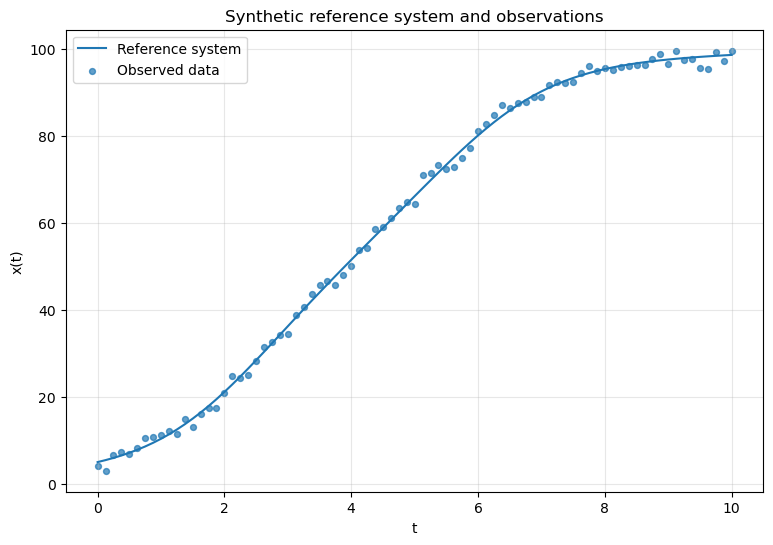

In [3]:
plt.figure(figsize=(9, 6))
plt.plot(
    data["t"],
    data["y_reference"],
    label="Reference system"
)
plt.scatter(
    data["t"],
    data["y_observed"],
    s=18,
    alpha=0.7,
    label="Observed data"
)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Synthetic reference system and observations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 7. Data split за дослідницькою роллю

Random split для time-dependent system може змішати майбутнє з минулим.

Тому використовуємо explicit temporal design.

### Training domain

$$
0\le t\le6.
$$

Усередині нього кожну четверту observation point залишаємо як *interpolation test*.

### Extrapolation domain

$$
6<t\le10.
$$

Ці observations не використовуються для fitting.

Отже, ми окремо перевіряємо:

$$
\text{interpolation}
\neq
\text{extrapolation}.
$$

In [4]:
training_domain = data[
    data["t"] <= 6.0
].copy()

training_domain["index_in_domain"] = np.arange(
    len(training_domain)
)

interp_mask = (
    training_domain["index_in_domain"] % 4 == 0
)

interp_test = training_domain[
    interp_mask
].copy()

train = training_domain[
    ~interp_mask
].copy()

extrap_test = data[
    data["t"] > 6.0
].copy()

print("Training points:", len(train))
print("Interpolation test points:", len(interp_test))
print("Extrapolation test points:", len(extrap_test))

Training points: 36
Interpolation test points: 13
Extrapolation test points: 32


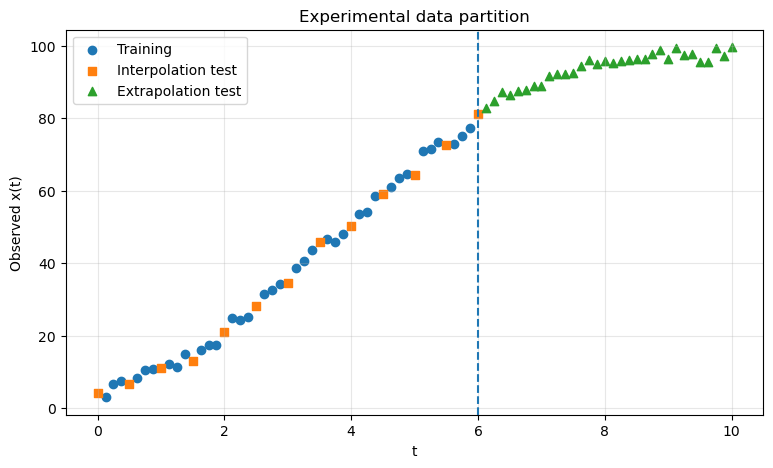

In [5]:
plt.figure(figsize=(9, 5))
plt.scatter(
    train["t"],
    train["y_observed"],
    label="Training"
)
plt.scatter(
    interp_test["t"],
    interp_test["y_observed"],
    marker="s",
    label="Interpolation test"
)
plt.scatter(
    extrap_test["t"],
    extrap_test["y_observed"],
    marker="^",
    label="Extrapolation test"
)
plt.axvline(
    6.0,
    linestyle="--"
)
plt.xlabel("t")
plt.ylabel("Observed x(t)")
plt.title("Experimental data partition")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 8. Mechanistic baseline

Baseline model:

$$
\frac{dx}{dt}
=
rx
\left(
1-\frac{x}{K}
\right).
$$

Вона має правильну загальну saturation structure, але не містить time-varying growth rate.

Калібруємо $r$ і $K$ *лише* на training data.

In [6]:
def logistic_exact(t, r, K, x0=X0):
    t = np.asarray(t)

    factor = (
        K - x0
    ) / x0

    return K / (
        1
        + factor * np.exp(
            -r * t
        )
    )

def mechanistic_loss(params):
    r, K = params

    if r <= 0 or K <= X0:
        return np.inf

    pred = logistic_exact(
        train["t"].to_numpy(),
        r,
        K
    )

    return np.sum(
        (
            train["y_observed"].to_numpy()
            - pred
        ) ** 2
    )

fit = minimize(
    mechanistic_loss,
    x0=np.array([0.6, 90.0]),
    method="L-BFGS-B",
    bounds=[
        (0.05, 2.0),
        (20.0, 200.0)
    ]
)

R_HAT, K_HAT = fit.x

print(
    "Calibrated r:",
    round(R_HAT, 4)
)
print(
    "Calibrated K:",
    round(K_HAT, 4)
)

Calibrated r: 0.8073
Calibrated K: 86.9607


# 9. Systematic discrepancy

Для training points:

$$
\delta_i
=
y_i
-
\hat y_{M,i}.
$$

Якщо residuals містять structure, baseline model не пояснює частину systematic behavior.

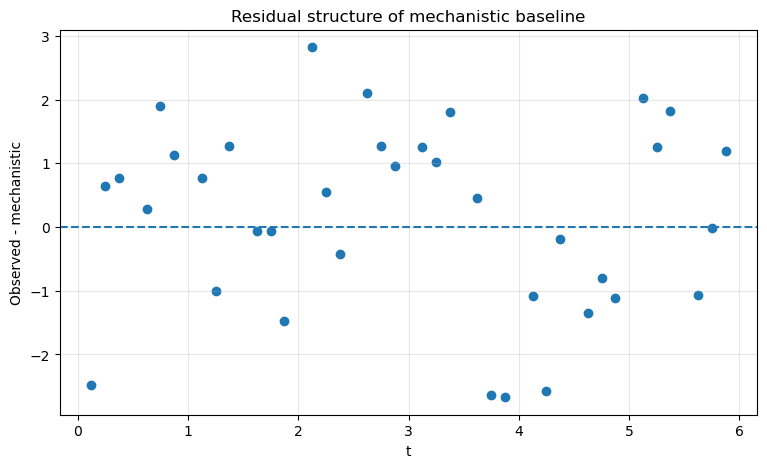

In [7]:
train["mechanistic"] = logistic_exact(
    train["t"].to_numpy(),
    R_HAT,
    K_HAT
)

train["residual_mech"] = (
    train["y_observed"]
    - train["mechanistic"]
)

plt.figure(figsize=(9, 5))
plt.scatter(
    train["t"],
    train["residual_mech"]
)
plt.axhline(
    0.0,
    linestyle="--"
)
plt.xlabel("t")
plt.ylabel("Observed - mechanistic")
plt.title("Residual structure of mechanistic baseline")
plt.grid(alpha=0.3)
plt.show()

## Завдання 9.1

Поясніть:

1. чи residuals виглядають purely random;
2. який pattern може вказувати на structural discrepancy;
3. чому calibration parameters можуть частково компенсувати misspecification;
4. чому малий training error не є достатнім аргументом для зміни model structure.

# 10. Purely data-driven model

Побудуємо simple polynomial Ridge regression:

$$
\hat y_D
=
g(t;\phi).
$$

Це навмисно проста модель. Мета ЛР -- не оптимізувати ML pipeline, а порівняти *джерела inductive bias*.

Polynomial model не знає:

- logistic growth mechanism;
- positivity;
- saturation;
- carrying capacity.

Вона знає лише training pairs

$$
(t_i,y_i).
$$

In [8]:
data_driven_model = make_pipeline(
    PolynomialFeatures(
        degree=4,
        include_bias=False
    ),
    Ridge(alpha=0.1)
)

data_driven_model.fit(
    train[["t"]],
    train["y_observed"]
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('polynomialfeatures', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",4
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True


# 11. Residual hybrid model

Hybrid formulation:

$$
\hat y_H(t)
=
\hat y_M(t)
+
\hat\delta(t).
$$

Correction model навчається не на full output, а на residual:

$$
\delta_i
=
y_i-\hat y_M(t_i).
$$

Для correction використаємо features:

$$
z(t)
=
\left[
t,
\hat y_M(t)
\right].
$$

Тобто data-driven component отримує information і про time, і про mechanistic state.

In [9]:
def hybrid_features(t):
    t = np.asarray(t)

    mech = logistic_exact(
        t,
        R_HAT,
        K_HAT
    )

    return np.column_stack([
        t,
        mech
    ])

hybrid_correction = make_pipeline(
    PolynomialFeatures(
        degree=2,
        include_bias=False
    ),
    Ridge(alpha=1.0)
)

hybrid_correction.fit(
    hybrid_features(
        train["t"].to_numpy()
    ),
    train["residual_mech"].to_numpy()
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('polynomialfeatures', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True


# 12. Єдиний prediction interface

Порівнюємо три model classes за однакових evaluation conditions.

In [10]:
def predict_mechanistic(t):
    return logistic_exact(
        np.asarray(t),
        R_HAT,
        K_HAT
    )

def predict_data_driven(t):
    t = np.asarray(t)

    return data_driven_model.predict(
        pd.DataFrame(
            {"t": t}
        )
    )

def predict_hybrid(t):
    t = np.asarray(t)

    mech = predict_mechanistic(t)

    correction = hybrid_correction.predict(
        hybrid_features(t)
    )

    return mech + correction

# 13. Візуальне порівняння моделей

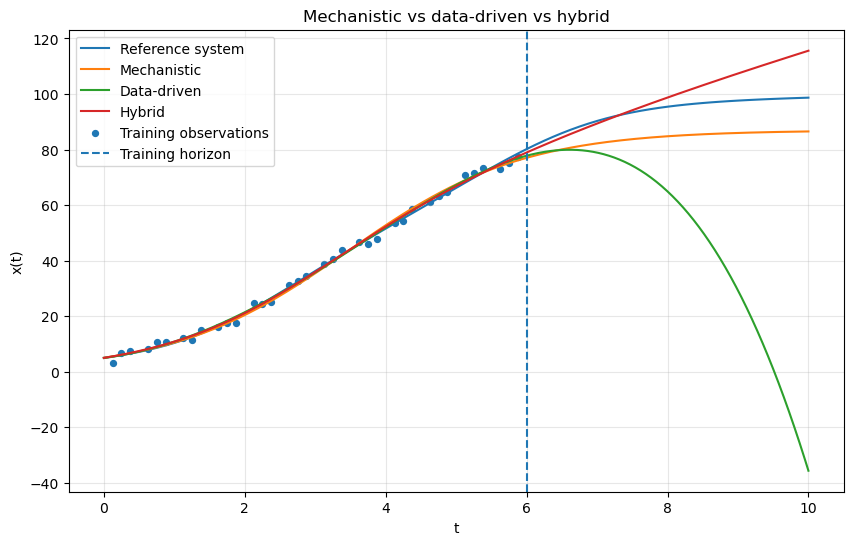

In [11]:
t_dense = np.linspace(
    0.0,
    10.0,
    400
)

plt.figure(figsize=(10, 6))

plt.plot(
    data["t"],
    data["y_reference"],
    label="Reference system"
)

plt.plot(
    t_dense,
    predict_mechanistic(t_dense),
    label="Mechanistic"
)

plt.plot(
    t_dense,
    predict_data_driven(t_dense),
    label="Data-driven"
)

plt.plot(
    t_dense,
    predict_hybrid(t_dense),
    label="Hybrid"
)

plt.scatter(
    train["t"],
    train["y_observed"],
    s=18,
    label="Training observations"
)

plt.axvline(
    6.0,
    linestyle="--",
    label="Training horizon"
)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Mechanistic vs data-driven vs hybrid")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 14. Metrics

Для кожного regime обчислимо:

$$
RMSE
=
\sqrt{
\frac{1}{n}
\sum_i
(y_i-\hat y_i)^2
},
$$

$$
MAE
=
\frac{1}{n}
\sum_i
|y_i-\hat y_i|,
$$

$$
E_{max}
=
\max_i
|y_i-\hat y_i|.
$$

Одна metric не повинна визначати весь scientific conclusion.

In [12]:
def evaluate_model(
    name,
    predictor,
    frame,
    regime
):
    y_true = frame[
        "y_observed"
    ].to_numpy()

    y_pred = predictor(
        frame["t"].to_numpy()
    )

    return {
        "model": name,
        "regime": regime,
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),
        "MaxAbsError": np.max(
            np.abs(
                y_true - y_pred
            )
        )
    }

models = {
    "Mechanistic": predict_mechanistic,
    "Data-driven": predict_data_driven,
    "Hybrid": predict_hybrid
}

regimes = {
    "Training": train,
    "Interpolation": interp_test,
    "Extrapolation": extrap_test
}

results = []

for model_name, predictor in models.items():
    for regime_name, frame in regimes.items():
        results.append(
            evaluate_model(
                model_name,
                predictor,
                frame,
                regime_name
            )
        )

metrics = pd.DataFrame(results)

metrics.round(4)

,model,regime,RMSE,MAE,MaxAbsError
0,Mechanistic,Training,1.4557,1.2314,2.8238
1,Mechanistic,Interpolation,1.8600,1.5123,4.2034
2,Mechanistic,Extrapolation,10.0183,9.7708,13.4058
3,Data-driven,Training,1.2958,1.1302,2.4518
4,Data-driven,Interpolation,1.6899,1.3550,3.4394
5,Data-driven,Extrapolation,59.1286,45.1616,135.3106
6,Hybrid,Training,1.3234,1.0949,2.5114
7,Hybrid,Interpolation,1.4432,1.2008,2.3167
8,Hybrid,Extrapolation,8.2485,6.1743,17.3128


In [13]:
pivot_rmse = metrics.pivot(
    index="model",
    columns="regime",
    values="RMSE"
)

pivot_rmse.round(4)

regime,Extrapolation,Interpolation,Training
model,,,
Data-driven,59.1286,1.6899,1.2958
Hybrid,8.2485,1.4432,1.3234
Mechanistic,10.0183,1.8600,1.4557


In [ ]:
pivot_rmse.plot(
    kind="bar",
    figsize=(9, 6)
)
plt.ylabel("RMSE")
plt.title("RMSE by model class and evaluation regime")
plt.xticks(rotation=0)
plt.grid(
    axis="y",
    alpha=0.3
)
plt.show()

## Завдання 14.1

Не обмежуйтеся фразою «модель X краща».

Для кожної model class поясніть:

1. training behavior;
2. interpolation behavior;
3. extrapolation behavior;
4. роль embedded assumptions;
5. чи підтримує experiment hypothesis $H_M$, $H_D$ або $H_H$;
6. які alternative explanations залишаються.

# 15. Error profiles

Aggregate metric може приховувати systematic error.

Тому аналізуємо:

$$
e(t)
=
y(t)-\hat y(t).
$$

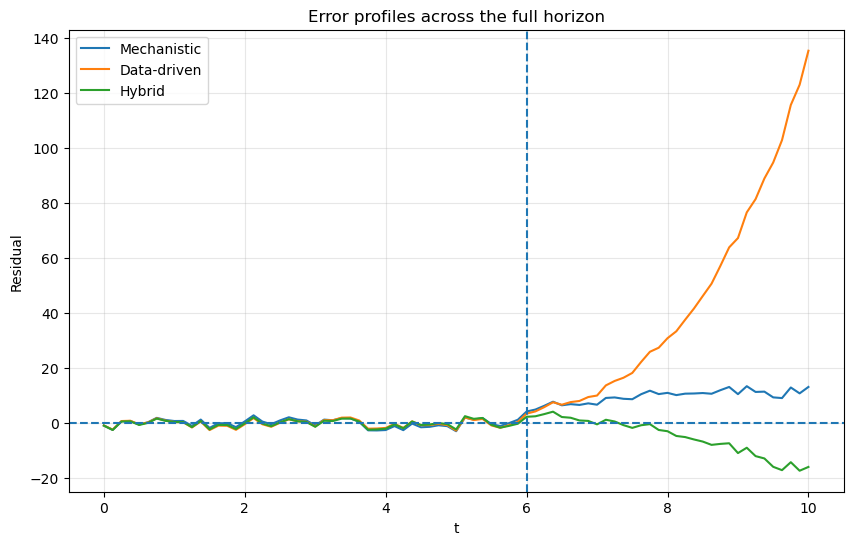

In [14]:
plt.figure(figsize=(10, 6))

for model_name, predictor in models.items():
    errors = (
        data["y_observed"].to_numpy()
        - predictor(
            data["t"].to_numpy()
        )
    )

    plt.plot(
        data["t"],
        errors,
        label=model_name
    )

plt.axhline(
    0.0,
    linestyle="--"
)
plt.axvline(
    6.0,
    linestyle="--"
)
plt.xlabel("t")
plt.ylabel("Residual")
plt.title("Error profiles across the full horizon")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 16. Factorial view of the experiment

Наш experiment має два factors:

$$
A=\text{ModelClass},
$$

$$
B=\text{EvaluationRegime}.
$$

Response:

$$
Y=RMSE.
$$

Тому comparison можна читати як factorial table, а не як три незалежні графіки.

Нас особливо цікавить interaction:

> Чи залежить effect model class від evaluation regime?

In [15]:
interaction_table = metrics.pivot(
    index="regime",
    columns="model",
    values="RMSE"
)

interaction_table.round(4)

model,Data-driven,Hybrid,Mechanistic
regime,,,
Extrapolation,59.1286,8.2485,10.0183
Interpolation,1.6899,1.4432,1.8600
Training,1.2958,1.3234,1.4557


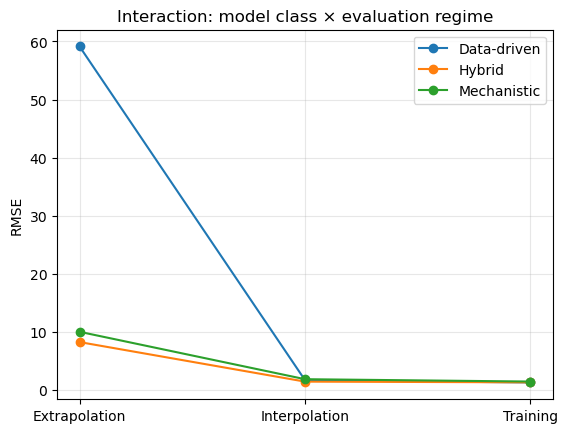

In [16]:
for model_name in interaction_table.columns:
    plt.plot(
        interaction_table.index,
        interaction_table[model_name],
        marker="o",
        label=model_name
    )

plt.ylabel("RMSE")
plt.title("Interaction: model class × evaluation regime")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Якщо relative ordering models змінюється між regimes, твердження

> «Model A краща за Model B»

є занадто загальним.

Коректніше:

> «Model A має менший error за Model B у regime $R$ за умов experiment $E$».

# 17. Додатковий factor -- training-data coverage

Тепер перевіримо, як hybrid correction залежить від amount of training information.

Використаємо training horizons:

$$
T_{train}
\in
\{
3,4,5,6
\}.
$$

Це новий experimental factor.

QoI:

$$
RMSE_{extra}.
$$

In [17]:
def fit_models_for_horizon(
    train_horizon
):
    domain = data[
        data["t"] <= train_horizon
    ].copy()

    domain["local_index"] = np.arange(
        len(domain)
    )

    held_out = (
        domain["local_index"] % 4 == 0
    )

    local_train = domain[
        ~held_out
    ].copy()

    def local_loss(params):
        r, K = params

        if r <= 0 or K <= X0:
            return np.inf

        pred = logistic_exact(
            local_train["t"].to_numpy(),
            r,
            K
        )

        return np.sum(
            (
                local_train["y_observed"].to_numpy()
                - pred
            ) ** 2
        )

    local_fit = minimize(
        local_loss,
        x0=np.array([0.6, 90.0]),
        method="L-BFGS-B",
        bounds=[
            (0.05, 2.0),
            (20.0, 200.0)
        ]
    )

    r_hat, k_hat = local_fit.x

    def mech(t):
        return logistic_exact(
            np.asarray(t),
            r_hat,
            k_hat
        )

    dd = make_pipeline(
        PolynomialFeatures(
            degree=4,
            include_bias=False
        ),
        Ridge(alpha=0.1)
    )

    dd.fit(
        local_train[["t"]],
        local_train["y_observed"]
    )

    residual = (
        local_train["y_observed"].to_numpy()
        - mech(
            local_train["t"].to_numpy()
        )
    )

    def h_features(t):
        t = np.asarray(t)
        return np.column_stack([
            t,
            mech(t)
        ])

    corr = make_pipeline(
        PolynomialFeatures(
            degree=2,
            include_bias=False
        ),
        Ridge(alpha=1.0)
    )

    corr.fit(
        h_features(
            local_train["t"].to_numpy()
        ),
        residual
    )

    def dd_predict(t):
        t = np.asarray(t)
        return dd.predict(
            pd.DataFrame({"t": t})
        )

    def hybrid_predict(t):
        t = np.asarray(t)
        return (
            mech(t)
            + corr.predict(
                h_features(t)
            )
        )

    test = data[
        data["t"] > train_horizon
    ]

    rows = []

    for name, predictor in {
        "Mechanistic": mech,
        "Data-driven": dd_predict,
        "Hybrid": hybrid_predict
    }.items():
        y_true = test[
            "y_observed"
        ].to_numpy()

        y_pred = predictor(
            test["t"].to_numpy()
        )

        rows.append({
            "train_horizon": train_horizon,
            "model": name,
            "RMSE_future": np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            )
        })

    return rows

coverage_results = []

for horizon in [
    3.0,
    4.0,
    5.0,
    6.0
]:
    coverage_results.extend(
        fit_models_for_horizon(
            horizon
        )
    )

coverage_df = pd.DataFrame(
    coverage_results
)

coverage_df.round(4)

,train_horizon,model,RMSE_future
0,3.0,Mechanistic,5.3346
1,3.0,Data-driven,264.8807
2,3.0,Hybrid,72.9872
3,4.0,Mechanistic,19.9100
4,4.0,Data-driven,648.7354
5,4.0,Hybrid,225.6172
6,5.0,Mechanistic,14.4327
7,5.0,Data-driven,72.9404
8,5.0,Hybrid,31.7152
9,6.0,Mechanistic,10.0183


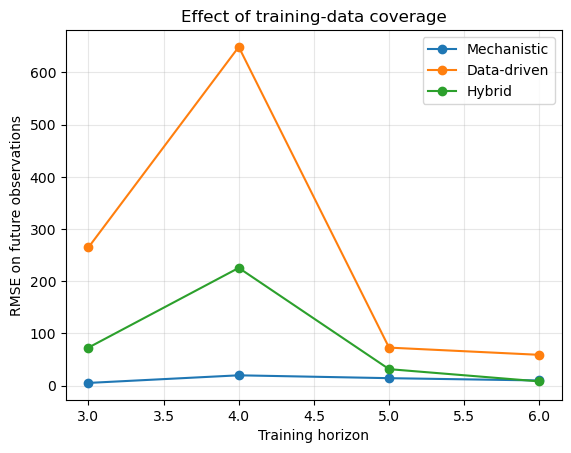

In [18]:
for model_name in coverage_df["model"].unique():
    subset = coverage_df[
        coverage_df["model"] == model_name
    ]

    plt.plot(
        subset["train_horizon"],
        subset["RMSE_future"],
        marker="o",
        label=model_name
    )

plt.xlabel("Training horizon")
plt.ylabel("RMSE on future observations")
plt.title("Effect of training-data coverage")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Завдання 17.1

Проаналізуйте:

1. як coverage data впливає на кожну model class;
2. чи hybrid advantage є стабільною;
3. чи змінюється conclusion зі зміною training horizon;
4. чи можна з цього experiment робити висновок про будь-які hybrid models;
5. який наступний experiment Ви б поставили для discriminating hypotheses.

# 18. Structural prior як джерело inductive bias

Mechanistic model обмежує solution space через equations.

Data-driven model обмежує solution space через:

- model class;
- regularization;
- feature representation;
- training data.

Hybrid model поєднує обидва джерела.

Схематично:

$$
\text{prediction}
=
\text{structure from knowledge}
+
\text{correction from data}.
$$

Але correction може:

- виправляти systematic discrepancy;
- fit noise;
- компенсувати неправильні parameters;
- приховувати помилкову structure.

Тому hybrid accuracy сама по собі не доводить правильність mechanistic part.

# 19. Чого не можна стверджувати

Навіть якщо hybrid має найменший RMSE у нашому experiment, не можна автоматично стверджувати:

- hybrid models завжди кращі;
- correction відновила справжній physical mechanism;
- mechanistic model стала правильною;
- extrapolation буде надійною за будь-якого horizon;
- learned residual переноситься на інші regimes.

Наш evidence стосується лише:

$$
\text{model classes}
+
\text{data}
+
\text{design space}
+
\text{metrics}
+
\text{evaluation regimes}.
$$

# 20. Bounded comparative statement

Заповніть:

> У межах synthetic system ________, training domain ________, evaluation regimes ________ та metrics ________ model class ________ продемонструвала ________. Це підтримує hypothesis ________ щодо ________, але не дозволяє стверджувати ________. Найважливішим наступним experiment є ________.

# Частина II. Перенесення на дисертаційне дослідження

# 21. Чи потрібна hybrid/data-driven модель?

Спочатку дайте відповідь:

> Яку конкретну limitation knowledge-driven model має компенсувати data-driven component?

Якщо відповіді немає, hybridization не є обґрунтованою.

Можливі ролі:

- residual correction;
- parameter estimation;
- unknown closure;
- surrogate;
- state estimation;
- data assimilation;
- regime classifier;
- learned constitutive relation.

# 22. Research Question

Сформулюйте RQ у формі comparison або effect question.

Наприклад:

> Чи покращує learned residual correction prediction QoI $Q$ відносно mechanistic baseline у validated regime без деградації robustness?

# 23. Competing hypotheses

Сформулюйте щонайменше дві hypotheses.

| Hypothesis | Mechanism / explanation | Prediction |
|---|---|---|
| $H_1$ | | |
| $H_2$ | | |

# 24. Experimental Protocol

| Поле | Специфікація |
|---|---|
| Research Question | |
| Hypotheses | |
| Model versions | |
| Factors | |
| Levels / ranges | |
| Controls | |
| QoI | |
| Data split logic | |
| Replications | |
| Randomization / CRN | |
| Metrics | |
| Analysis plan | |
| Inference rule | |
| Domain of validity | |
| Computational budget | |
| Reproducibility metadata | |

# 25. Knowledge-driven baseline

Зафіксуйте:

$$
\hat y_M
=
M(\mathbf x;\hat\theta).
$$

Опишіть:

- equations / rules;
- calibrated parameters;
- validated domain;
- known discrepancy;
- credibility evidence з ЛР6.

# 26. Data-driven baseline

Визначте:

$$
\hat y_D
=
g(\mathbf x;\hat\phi).
$$

Обґрунтуйте:

- features;
- target;
- model class;
- regularization;
- split;
- metric.

Не використовуйте складну ML model, якщо simple baseline достатня для RQ.

# 27. Hybrid formulation

Запишіть architecture явно.

Наприклад:

$$
\hat y_H
=
M(\mathbf x;\hat\theta)
+
g(\mathbf z;\hat\phi).
$$

Визначте:

- що є $\mathbf z$;
- що саме вивчає $g$;
- які constraints зберігаються;
- які constraints можуть бути порушені;
- чи має correction scientific interpretation.

# 28. Data leakage audit

Перевірте:

- чи validation/test data не використовувалися для calibration;
- чи preprocessing fit лише на training data;
- чи temporal order не порушено;
- чи data одного experiment не потрапили одночасно у train/test;
- чи target-derived features не створюють leakage.

# 29. Comparative experiment

Порівняйте щонайменше:

1. mechanistic baseline;
2. data-driven baseline;
3. hybrid model.

За однакових:

- test data;
- QoI;
- metrics;
- evaluation regimes.

# 30. Generalization experiment

Виділіть хоча б два regimes:

$$
R_{in}
=
\text{interpolation / supported regime},
$$

$$
R_{out}
=
\text{extrapolation / shifted regime}.
$$

Порівняйте:

$$
E_{in}(M,D,H)
$$

та

$$
E_{out}(M,D,H).
$$

# 31. Robustness experiment

Змініть один додатковий factor:

- training-data volume;
- noise level;
- parameter uncertainty;
- initial condition;
- topology;
- scenario.

Перевірте, чи зберігається comparative conclusion.

# 32. Error audit

Не обмежуйтеся aggregate metric.

Дослідіть:

- residual pattern;
- bias;
- regime-specific error;
- extreme errors;
- failure cases.

# 33. Hybrid Experiment Specification v0.7

| Компонент | Специфікація |
|---|---|
| Research Question | |
| Competing hypotheses | |
| Intended use | |
| QoI | |
| Mechanistic model | |
| Data-driven model | |
| Hybrid architecture | |
| Role of learned component | |
| Training data | |
| Validation/test data | |
| Data split logic | |
| Experimental factors | |
| Controls | |
| Metrics | |
| Interpolation evidence | |
| Extrapolation evidence | |
| Robustness evidence | |
| Error audit | |
| Data leakage audit | |
| Domain of validity | |
| Comparative conclusion | |
| Unsupported claims | |
| Next discriminating experiment | |
| Reproducibility metadata | |

# 34. Підсумковий артефакт ЛР7

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Model Credibility<br/>Report v0.6") --> B("Experimental<br/>Protocol")
 B --> C("Mechanistic<br/>baseline")
 B --> D("Data-driven<br/>baseline")
 C --> E("Hybrid<br/>architecture")
 D --> F("Comparative<br/>experiment")
 E --> F
 C --> F
 F --> G("Generalization +<br/>robustness evidence")
 G --> H("Hybrid Experiment<br/>Specification v0.7")
```

# Контрольні питання

1. Що відрізняє computational experiment від набору simulation runs?
2. Що таке experimental factor?
3. Що таке control variable?
4. Чому QoI потрібно визначати до analysis?
5. Що таке knowledge-driven model?
6. Що таке data-driven model?
7. Що таке hybrid model?
8. Які ролі може виконувати learned component у hybrid model?
9. Що таке residual correction?
10. Чому residual structure може свідчити про model discrepancy?
11. Чому learned correction може приховувати неправильну mechanistic structure?
12. Що таке inductive bias?
13. Який inductive bias має mechanistic model?
14. Який inductive bias має data-driven model?
15. Чому simple ML baseline часто методично краща за складну model?
16. Чому random split може бути некоректним для time-dependent system?
17. Чим interpolation test відрізняється від extrapolation test?
18. Що таке data leakage?
19. Чому calibration/training data не слід використовувати як єдиний validation evidence?
20. Чому models потрібно порівнювати на однакових test conditions?
21. Чому одна aggregate metric недостатня?
22. Що показує residual profile?
23. Що означає interaction між model class та evaluation regime?
24. Як training-data coverage може змінити comparative conclusion?
25. Що таке robustness experiment?
26. Чому hybrid model із меншим RMSE не обов'язково має правильніший mechanism?
27. Чому extrapolation є сильнішим test, ніж interpolation?
28. Що таке competing hypotheses?
29. Що таке discriminating experiment?
30. Що означає bounded comparative claim?

# Вимоги до звіту

У `.ipynb` мають бути:

- Research Question;
- competing hypotheses;
- Experimental Protocol;
- mechanistic baseline;
- data-driven baseline;
- hybrid architecture;
- чітко визначена роль learned component;
- обґрунтований data split;
- data leakage audit;
- однакові metrics для трьох model classes;
- interpolation comparison;
- extrapolation comparison;
- щонайменше один robustness experiment;
- error profiles;
- comparative evidence table;
- bounded comparative statement;
- *Hybrid Experiment Specification v0.7*;
- висновки.

::: callout-important
## Критерій якості

Головне питання ЛР7:

$$
\boxed{
\text{Що саме ми дізналися завдяки дизайну experiment?}
}
$$

Не оцінюється «наявність ML» сама по собі.

Оцінюється логіка:

$$
RQ
\rightarrow
\text{design}
\rightarrow
\text{alternative models}
\rightarrow
\text{controlled comparison}
\rightarrow
\text{bounded inference}.
$$
:::

# Висновки

У висновках дайте відповіді:

1. Яке Research Question досліджувалося?
2. Які competing hypotheses сформульовано?
3. Які factors, controls і QoI визначено?
4. Яка limitation mechanistic baseline мотивувала hybridization?
5. Яку роль виконував data-driven component?
6. Як було організовано data split?
7. Як перевірено відсутність leakage?
8. Як models поводилися на training data?
9. Як models поводилися в interpolation regime?
10. Як models поводилися в extrapolation regime?
11. Чи залежав comparative result від evaluation regime?
12. Що показав robustness experiment?
13. Які systematic residual patterns залишилися?
14. Який bounded comparative claim підтримується?
15. Які твердження не підтримуються experiment?
16. Який наступний discriminating experiment доцільно провести?

# Джерела та корисні ресурси

Використовується спільна накопичувальна бібліографічна база курсу `mmss-references.bib`.

- [SciPy documentation](https://docs.scipy.org/doc/scipy/)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [pandas documentation](https://pandas.pydata.org/docs/)
- [scikit-learn documentation](https://scikit-learn.org/stable/)
- [Matplotlib documentation](https://matplotlib.org/stable/)

# References